# Bean-leaf disease spotter: a published vision model on real field photos

This notebook checks a ready-made image model. It looks at a photo of a bean leaf and says
whether the leaf is **healthy** or shows one of two common diseases, **angular leaf spot** or
**bean rust**. We do not train anything: we download a model that someone published, test it on
128 real field photos from Uganda that it has never seen, compare it with a "guessing" baseline,
check *where* in the photo it looked, and save everything a web service would need.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/snow10100/aie113-projects/blob/main/tracks/vision/notebook.ipynb)

The full explanation, for people who have never seen machine learning:
[README.md](README.md) (English) · [README.ar.md](README.ar.md) (العربية).

**Setup.** Colab already has PyTorch, `transformers` and the other libraries we use; this cell
only installs the Hugging Face `datasets` library if it is missing. On your own computer,
install `requirements.txt` first.

In [1]:
import importlib.util

if importlib.util.find_spec("datasets") is None:
    %pip install -q datasets

**Settings.** Everything you might want to change is a constant here: which model, which photos,
how many to test, and where to save the results. Fixed seeds keep every run the same.

In [2]:
import os
os.environ["DISABLE_SAFETENSORS_CONVERSION"] = "1"  # the model is stored as an older .bin file: do not fetch a converted copy in the background

import json
import random
import time
from datetime import date

import datasets
import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoImageProcessor, AutoModelForImageClassification

%config InlineBackend.figure_formats = ["jpeg"]

MODEL_ID = "nateraw/vit-base-beans"     # published on Hugging Face, licence Apache-2.0
DATASET_ID = "AI-Lab-Makerere/beans"    # field photos from Uganda, licence MIT
TEST_FILES = "data/test-*.parquet"      # only the test photos: we do not train
MAX_TEST_PHOTOS = 128                   # 128 = the whole test split; lower it for a quicker run
BATCH_SIZE = 16
IMAGE_SIZE = 224                        # the model sees 224 x 224 pixels
PATCH = 32                              # size of the grey square used for the explanation
STRIDE = 16                             # how far the grey square moves each time
NOT_SURE_BELOW = 0.80                   # answers less confident than this could say "not sure"
SAMPLE_PHOTO = 50                       # the test photo scored at the end
ARTIFACTS_DIR = "artifacts"
MODEL_VERSION = "1.0.0"
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
transformers.logging.disable_progress_bar()
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__, "| device:", DEVICE)

torch 2.15.0+cpu | transformers 5.24.0 | datasets 5.2.0 | device: cpu


**Load the test photos and take a quick look.** We download only the *test* part of the beans
dataset (128 photos, 18 MB), because we do not train. One example is one photo of one leaf, with
the label an expert gave it. A warning about `HF_TOKEN` is harmless: these downloads are public
and need no account.

In [3]:
# Explicit parquet loading avoids datasets>=5 expecting unrelated train/validation splits.
data_revision = "27aa014ce09b193e1a6f58112d4a66e0eddb69c5"
test_ds = load_dataset("parquet", data_files={"test": f"hf://datasets/{DATASET_ID}@{data_revision}/data/test-00000-of-00001.parquet"}, split="test")
assert len(test_ds) == 128, "Expected the complete 128-photo test split"
test_ds = test_ds.select(range(min(MAX_TEST_PHOTOS, len(test_ds))))

label_names = test_ds.features["labels"].names
labels = list(test_ds["labels"])

look = pd.DataFrame({
    "file": [os.path.basename(path) for path in test_ds["image_file_path"]],
    "label": [label_names[y] for y in labels],
})
print(len(test_ds), "test photos | labels:", label_names)
print(look["label"].value_counts().to_string())
print("photo sizes (width, height):", {test_ds[i]["image"].size for i in range(len(test_ds))})
look.head()

128 test photos | labels: ['angular_leaf_spot', 'bean_rust', 'healthy']
label
angular_leaf_spot    43
bean_rust            43
healthy              42


photo sizes (width, height): {(500, 500)}


,file,label
0,angular_leaf_spot_test.0.jpg,angular_leaf_spot
1,angular_leaf_spot_test.1.jpg,angular_leaf_spot
2,angular_leaf_spot_test.10.jpg,angular_leaf_spot
3,angular_leaf_spot_test.11.jpg,angular_leaf_spot
4,angular_leaf_spot_test.12.jpg,angular_leaf_spot


**Load the published model and its photo preparation.** The model comes with its own preparation
step, which plays the role of "features": every photo is resized to 224 × 224 pixels and its
colours become numbers between -1 and 1. A service must prepare photos in exactly the same way.

In [4]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageClassification.from_pretrained(MODEL_ID).to(DEVICE).eval()
model_revision = HfApi().model_info(MODEL_ID).sha
n_params = sum(p.numel() for p in model.parameters())
print(f"model: {MODEL_ID} (revision {model_revision[:7]}), {n_params / 1e6:.1f} million numbers, about {n_params * 4 / 1e6:.0f} MB")
print("model labels:", model.config.id2label)
assert [model.config.id2label[k] for k in range(len(label_names))] == label_names, "model and photos use a different label order"

print(f"photo preparation: resize to {processor.size['width']} x {processor.size['height']} pixels | colour mean {list(processor.image_mean)} | colour std {list(processor.image_std)}")
assert processor.size["height"] == processor.size["width"] == IMAGE_SIZE, "IMAGE_SIZE does not match the model"
pixel_values = processor(images=test_ds[0]["image"].convert("RGB"), return_tensors="pt")["pixel_values"]
print("what the model receives for one photo:", tuple(pixel_values.shape),
      "| numbers between", round(pixel_values.min().item(), 2), "and", round(pixel_values.max().item(), 2))

model: nateraw/vit-base-beans (revision 41f85ac), 85.8 million numbers, about 343 MB
model labels: {0: 'angular_leaf_spot', 1: 'bean_rust', 2: 'healthy'}
photo preparation: resize to 224 x 224 pixels | colour mean [0.5, 0.5, 0.5] | colour std [0.5, 0.5, 0.5]
what the model receives for one photo: (1, 3, 224, 224) | numbers between -1.0 and 0.92


**A few photos with the model's answers.** Two photos of each kind, with the expert's label, the
model's answer and how sure the model is.

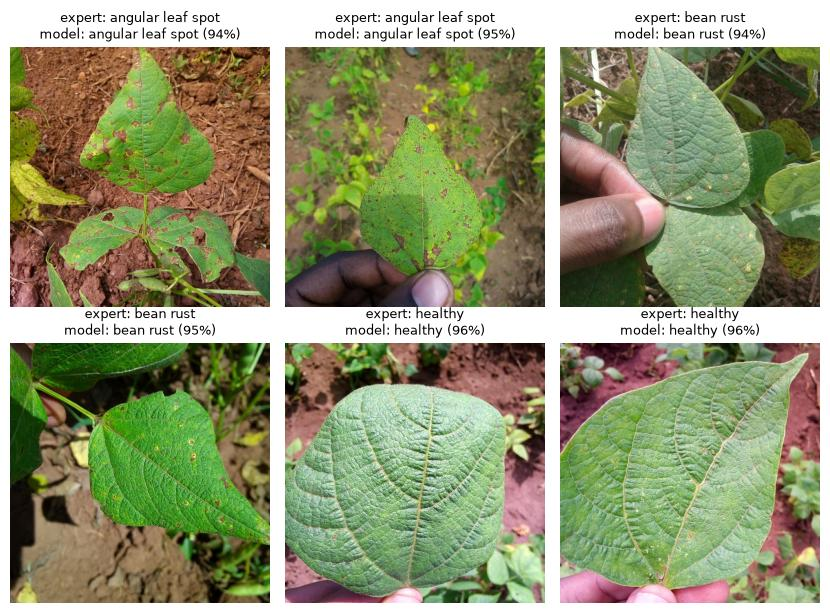

In [5]:
gallery = []
for k in range(len(label_names)):
    gallery += [i for i, y in enumerate(labels) if y == k][:2]   # the first two photos of each label
photos = [test_ds[i]["image"].convert("RGB") for i in gallery]
inputs = processor(images=photos, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    probs = model(**inputs).logits.softmax(dim=-1).cpu()

fig, axes = plt.subplots(2, 3, figsize=(8.4, 6.2))
for ax, i, photo, p in zip(axes.flat, gallery, photos, probs):
    k = int(p.argmax())
    ax.imshow(photo)
    ax.set_title(f"expert: {label_names[labels[i]].replace('_', ' ')}\n"
                 f"model: {model.config.id2label[k].replace('_', ' ')} ({float(p[k]):.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**How often is it right?** We score every test photo and count the right answers (accuracy). The
baseline is a "model" that always gives the most common answer: a useful model must beat it by far.

In [6]:
start = time.time()
all_probs = []
for i in range(0, len(test_ds), BATCH_SIZE):
    batch = test_ds[i : i + BATCH_SIZE]
    inputs = processor(images=[photo.convert("RGB") for photo in batch["image"]], return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        all_probs.append(model(**inputs).logits.softmax(dim=-1).cpu())
all_probs = torch.cat(all_probs).numpy()
seconds = time.time() - start

results = look.copy()
results["predicted"] = [model.config.id2label[int(k)] for k in all_probs.argmax(axis=1)]
results["confidence"] = all_probs.max(axis=1).round(3)
results["correct"] = results["label"] == results["predicted"]
accuracy = results["correct"].mean()

most_common = results["label"].value_counts().idxmax()
baseline_accuracy = (results["label"] == most_common).mean()
unsure = results["confidence"] < NOT_SURE_BELOW

print(f"scored {len(results)} photos in {seconds:.0f} s ({seconds / len(results):.2f} s per photo on {DEVICE})")
print(f"model accuracy:    {accuracy:.1%} ({results['correct'].sum()} of {len(results)} right)")
print(f"baseline accuracy: {baseline_accuracy:.1%} (always answer '{most_common}')")
print(f"average confidence: {results.loc[results['correct'], 'confidence'].mean():.0%} when right, "
      f"{results.loc[~results['correct'], 'confidence'].mean():.0%} when wrong (lowest {results['confidence'].min():.0%}, highest {results['confidence'].max():.0%})")
print(f"below {NOT_SURE_BELOW:.0%} confidence: {unsure.sum()} answers, of which {(unsure & ~results['correct']).sum()} wrong "
      f"(out of {(~results['correct']).sum()} wrong answers in total)")

scored 128 photos in 40 s (0.31 s per photo on cpu)
model accuracy:    96.9% (124 of 128 right)
baseline accuracy: 33.6% (always answer 'angular_leaf_spot')
average confidence: 94% when right, 81% when wrong (lowest 63%, highest 96%)
below 80% confidence: 2 answers, of which 2 wrong (out of 4 wrong answers in total)


**Which mistakes does it make?** The table counts, for each expert label (rows), what the model
answered (columns). The sentences say the same in words, and the last table lists every mistake.

In [7]:
confusion = pd.crosstab(results["label"], results["predicted"]).reindex(index=label_names, columns=label_names, fill_value=0)
print(confusion.to_string(), "\n")
for true_label in label_names:
    row = confusion.loc[true_label]
    others = [f"{row[p]} {p}" for p in label_names if p != true_label and row[p] > 0]
    print(f"Of {row.sum()} {true_label} photos, the model got {row[true_label]} right"
          + (f" and called {' and '.join(others)}." if others else "."))
results[~results["correct"]]

predicted          angular_leaf_spot  bean_rust  healthy
label                                                   
angular_leaf_spot                 40          3        0
bean_rust                          0         43        0
healthy                            0          1       41 

Of 43 angular_leaf_spot photos, the model got 40 right and called 3 bean_rust.
Of 43 bean_rust photos, the model got 43 right.
Of 42 healthy photos, the model got 41 right and called 1 bean_rust.


,file,label,predicted,confidence,correct
6,angular_leaf_spot_test.14.jpg,angular_leaf_spot,bean_rust,0.754,False
30,angular_leaf_spot_test.36.jpg,angular_leaf_spot,bean_rust,0.939,False
37,angular_leaf_spot_test.42.jpg,angular_leaf_spot,bean_rust,0.937,False
115,healthy_test.35.jpg,healthy,bean_rust,0.626,False


## Why did the model say that?

We cover one small square of the photo with grey, ask the model again, and repeat for every
position (169 squares). Where covering a part makes the model much less sure, that part mattered.
When the model is about 95% sure, covering one small square changes almost nothing (it finds what
it needs in many places at once), so we explain the right answer it was least sure about, and its first mistake.

In [8]:
right_and_sick = results[results["correct"] & (results["label"] != "healthy")]
explain_ids = [int(right_and_sick["confidence"].idxmin())]                # the right answer it was least sure about
explain_ids += [int(i) for i in results.index[~results["correct"]][:1]]  # its first mistake, if there is one
positions = [(y, x) for y in range(0, IMAGE_SIZE - PATCH + 1, STRIDE) for x in range(0, IMAGE_SIZE - PATCH + 1, STRIDE)]

explanations = []
for idx in explain_ids:
    photo = test_ds[idx]["image"].convert("RGB")
    pixel_values = processor(images=photo, return_tensors="pt")["pixel_values"].to(DEVICE)
    with torch.no_grad():
        probs = model(pixel_values=pixel_values).logits.softmax(dim=-1)[0].cpu()
    k = int(probs.argmax())

    covered = pixel_values.repeat(len(positions), 1, 1, 1)
    for n, (y, x) in enumerate(positions):
        covered[n, :, y : y + PATCH, x : x + PATCH] = 0.0   # 0 is mid-grey after the colour scaling (mean 0.5, std 0.5)
    covered_probs = []
    with torch.no_grad():
        for i in range(0, len(covered), BATCH_SIZE):
            covered_probs.append(model(pixel_values=covered[i : i + BATCH_SIZE]).logits.softmax(dim=-1)[:, k].cpu())
    drops = probs[k].item() - torch.cat(covered_probs).numpy()

    heat = np.zeros((IMAGE_SIZE, IMAGE_SIZE))
    count = np.zeros((IMAGE_SIZE, IMAGE_SIZE))
    for (y, x), d in zip(positions, drops):
        heat[y : y + PATCH, x : x + PATCH] += d
        count[y : y + PATCH, x : x + PATCH] += 1
    explanations.append({"idx": idx, "photo": photo.resize((IMAGE_SIZE, IMAGE_SIZE)), "label": model.config.id2label[k],
                         "confidence": probs[k].item(), "drops": drops, "heat": heat / count})
    print(f"photo {idx}: expert says {results.loc[idx, 'label']}, model says {model.config.id2label[k]} "
          f"({probs[k].item():.0%}); scored {len(positions)} covered versions")

photo 27: expert says angular_leaf_spot, model says angular_leaf_spot (81%); scored 169 covered versions


photo 6: expert says angular_leaf_spot, model says bean_rust (75%); scored 169 covered versions


**Where the model looked.** Left: the photo. Right: the same photo in grey, with blue where
covering it lowered the model's confidence the most. The sentences under the plot say it in words.

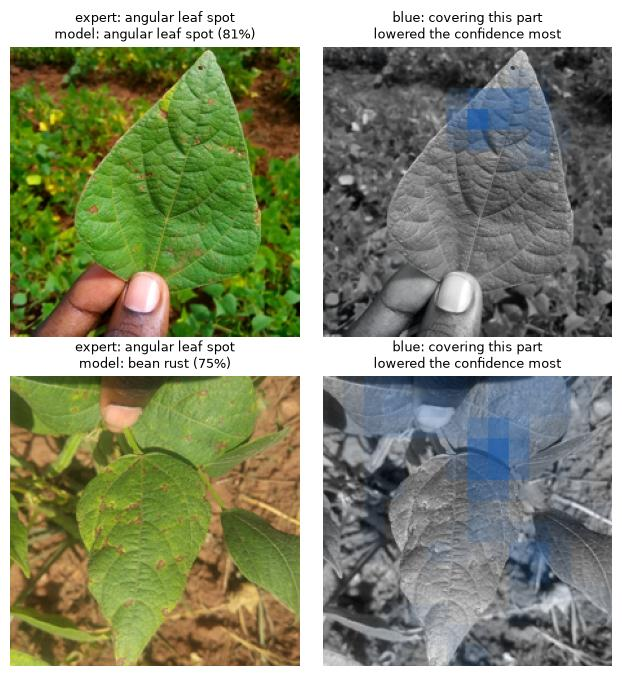

Photo 27 (model says angular_leaf_spot, 81% sure): the area that matters most is the top-centre of the photo; covering it there drops the confidence to 30%. 13 of 169 grey squares lowered it by more than 5 points.
Photo 6 (model says bean_rust, 75% sure): the area that matters most is the top-centre of the photo; covering it there drops the confidence to 22%. 70 of 169 grey squares lowered it by more than 5 points.


In [9]:
fig, axes = plt.subplots(len(explanations), 2, figsize=(6.4, 3.4 * len(explanations)), squeeze=False)
for row, e in zip(axes, explanations):
    strength = np.clip(e["heat"], 0, None) / max(e["heat"].max(), 0.10)   # stays faint if nothing lowers the confidence by 10 points
    overlay = np.zeros((IMAGE_SIZE, IMAGE_SIZE, 4))
    overlay[..., :3] = [0.11, 0.36, 0.67]   # one blue
    overlay[..., 3] = 0.85 * strength
    row[0].imshow(e["photo"])
    row[0].set_title(f"expert: {results.loc[e['idx'], 'label'].replace('_', ' ')}\n"
                     f"model: {e['label'].replace('_', ' ')} ({e['confidence']:.0%})", fontsize=9)
    row[1].imshow(e["photo"].convert("L"), cmap="gray")
    row[1].imshow(overlay)
    row[1].set_title("blue: covering this part\nlowered the confidence most", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

for e in explanations:
    y, x = np.unravel_index(e["heat"].argmax(), e["heat"].shape)
    where = ["top", "middle", "bottom"][y * 3 // IMAGE_SIZE] + "-" + ["left", "centre", "right"][x * 3 // IMAGE_SIZE]
    where = "centre" if where == "middle-centre" else where
    print(f"Photo {e['idx']} (model says {e['label']}, {e['confidence']:.0%} sure): the area that matters most is the {where} "
          f"of the photo; covering it there drops the confidence to {e['confidence'] - e['drops'].max():.0%}. "
          f"{(e['drops'] > 0.05).sum()} of {len(e['drops'])} grey squares lowered it by more than 5 points.")

**Save what a service needs.** The model files (about 340 MB: git ignores `artifacts/`) and a
small JSON with the version, the labels, the photo size and the test numbers. With 86 million
numbers the model needs full PyTorch here; a service could convert it to ONNX and run it with the
much smaller ONNX Runtime instead, an idea for the container stage.

In [10]:
os.makedirs(ARTIFACTS_DIR, exist_ok=True)
model.save_pretrained(f"{ARTIFACTS_DIR}/model")
processor.save_pretrained(f"{ARTIFACTS_DIR}/model")

model_info = {
    "model_version": MODEL_VERSION,
    "base_model": MODEL_ID,
    "base_model_revision": model_revision,
    "licences": {"model": "Apache-2.0", "photos": "MIT"},
    "created": date.today().isoformat(),
    "labels": label_names,
    "feature_names": ["pixel_values"],
    "input": {"image_size": [IMAGE_SIZE, IMAGE_SIZE], "colour_mean": list(processor.image_mean), "colour_std": list(processor.image_std),
              "image_processor": type(processor).__name__},
    "n_parameters": n_params,
    "training_data": "beans train split, 1,034 photos (trained by the model's author, not in this notebook)",
    "eval_data": {"dataset": DATASET_ID, "revision": data_revision, "split": "test", "n_photos": len(results)},
    "metrics": {
        "accuracy": round(float(accuracy), 4),
        "baseline_accuracy": round(float(baseline_accuracy), 4),
        "baseline": f"always answer {most_common}",
        "recall_per_label": {k: round(float(confusion.loc[k, k] / confusion.loc[k].sum()), 4) for k in label_names},
        "confusion": {k: {p: int(confusion.loc[k, p]) for p in label_names} for k in label_names},
        "not_sure_below": NOT_SURE_BELOW,
        "seconds_per_photo": round(seconds / len(results), 3),
        "device": DEVICE,
    },
}
with open(f"{ARTIFACTS_DIR}/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

saved_files = [f"{ARTIFACTS_DIR}/model/{name}" for name in sorted(os.listdir(f"{ARTIFACTS_DIR}/model"))] + [f"{ARTIFACTS_DIR}/model_info.json"]
for path in saved_files:
    size_mb = os.path.getsize(path) / 1e6
    print(f"{path}: {size_mb:.1f} MB" if size_mb >= 0.1 else f"{path}: less than 0.1 MB")
print(json.dumps(model_info["metrics"]))

artifacts/model/config.json: less than 0.1 MB
artifacts/model/model.safetensors: 343.2 MB
artifacts/model/preprocessor_config.json: less than 0.1 MB
artifacts/model_info.json: less than 0.1 MB
{"accuracy": 0.9688, "baseline_accuracy": 0.3359, "baseline": "always answer angular_leaf_spot", "recall_per_label": {"angular_leaf_spot": 0.9302, "bean_rust": 1.0, "healthy": 0.9762}, "confusion": {"angular_leaf_spot": {"angular_leaf_spot": 40, "bean_rust": 3, "healthy": 0}, "bean_rust": {"angular_leaf_spot": 0, "bean_rust": 43, "healthy": 0}, "healthy": {"angular_leaf_spot": 0, "bean_rust": 1, "healthy": 41}}, "not_sure_below": 0.8, "seconds_per_photo": 0.311, "device": "cpu"}


**Score one new photo, the way a service would.** We reload the saved model from `artifacts/`,
prepare one photo exactly as before, and return the answer as a small dictionary, close to what an
API would send back.

In [11]:
service_processor = AutoImageProcessor.from_pretrained(f"{ARTIFACTS_DIR}/model")
service_model = AutoModelForImageClassification.from_pretrained(f"{ARTIFACTS_DIR}/model").eval()
with open(f"{ARTIFACTS_DIR}/model_info.json") as f:
    service_info = json.load(f)

new_photo = test_ds[SAMPLE_PHOTO]["image"]   # pretend a farmer has just uploaded this photo
inputs = service_processor(images=new_photo.convert("RGB"), return_tensors="pt")
with torch.no_grad():
    probs = service_model(**inputs).logits.softmax(dim=-1)[0]
k = int(probs.argmax())
answer = {
    "label": service_model.config.id2label[k],
    "confidence": round(float(probs[k]), 3),
    "scores": {service_model.config.id2label[j]: round(float(p), 3) for j, p in enumerate(probs)},
    "model_version": service_info["model_version"],
}
print("expert label:", label_names[labels[SAMPLE_PHOTO]])
print(json.dumps(answer, indent=2))

expert label: bean_rust
{
  "label": "bean_rust",
  "confidence": 0.845,
  "scores": {
    "angular_leaf_spot": 0.133,
    "bean_rust": 0.845,
    "healthy": 0.023
  },
  "model_version": "1.0.0"
}


## Your project starts here

This notebook works, but it is one long script. With your AI coding agent, turn it into a real
service, one stage at a time:

1. **Clean architecture:** split photo preparation, prediction and the explanation into small modules with clear jobs.
2. **FastAPI endpoint:** upload a leaf photo, get the label, the confidence, "not sure" when unsure, and the model version.
3. **Container:** package the service and the model in a Docker image (and ask whether ONNX Runtime makes it smaller).
4. **Tests:** check photo preparation, known photos giving known answers, and the "not sure" rule.
5. **GitHub Actions:** run the tests and build the image on every push.
6. **Secrets:** keep tokens such as `HF_TOKEN` out of the code and out of git.
7. **Optional front end:** a small Vite + React page to upload a photo and see the answer and where the model looked.

The stage-by-stage guide is [GUIDE.md](../../GUIDE.md) (Arabic: [GUIDE.ar.md](../../GUIDE.ar.md)).